Dataset shape: (1797, 64)
Visible units: 64
Epoch 01/30 | Reconstruction Error: 0.1467 | Free Energy: -30.5549
Epoch 02/30 | Reconstruction Error: 0.1294 | Free Energy: -30.5005
Epoch 03/30 | Reconstruction Error: 0.1289 | Free Energy: -30.2331
Epoch 04/30 | Reconstruction Error: 0.1289 | Free Energy: -30.0192
Epoch 05/30 | Reconstruction Error: 0.1287 | Free Energy: -30.3938
Epoch 06/30 | Reconstruction Error: 0.1285 | Free Energy: -30.2486
Epoch 07/30 | Reconstruction Error: 0.1282 | Free Energy: -30.3553
Epoch 08/30 | Reconstruction Error: 0.1280 | Free Energy: -30.2961
Epoch 09/30 | Reconstruction Error: 0.1276 | Free Energy: -30.1426
Epoch 10/30 | Reconstruction Error: 0.1269 | Free Energy: -30.2736
Epoch 11/30 | Reconstruction Error: 0.1256 | Free Energy: -30.2011
Epoch 12/30 | Reconstruction Error: 0.1236 | Free Energy: -30.5525
Epoch 13/30 | Reconstruction Error: 0.1208 | Free Energy: -30.6541
Epoch 14/30 | Reconstruction Error: 0.1177 | Free Energy: -31.3073
Epoch 15/30 | Reco

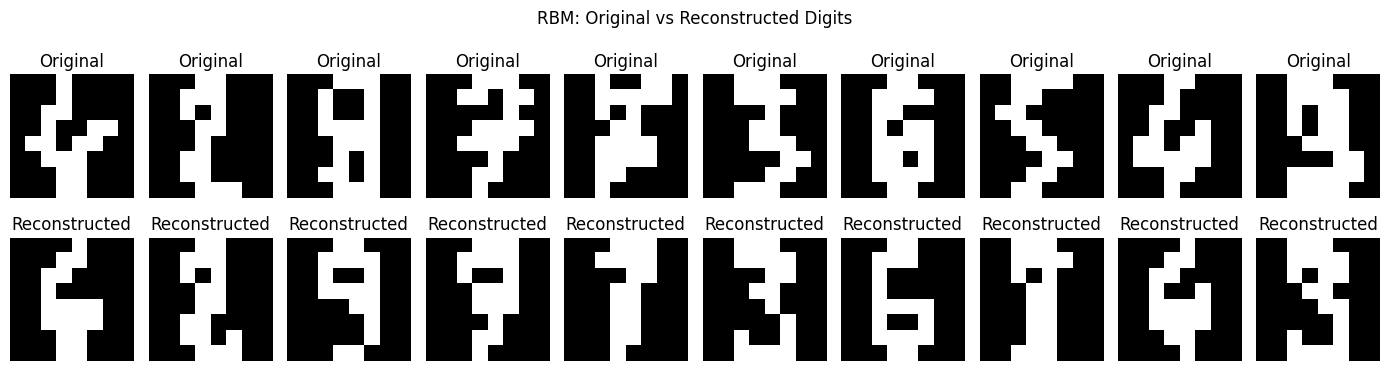

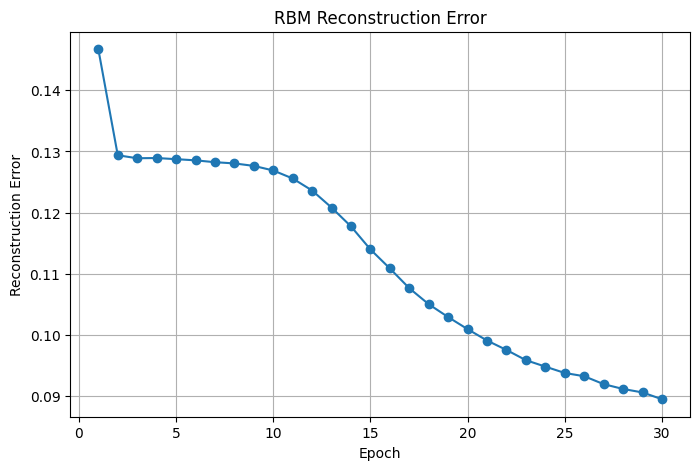

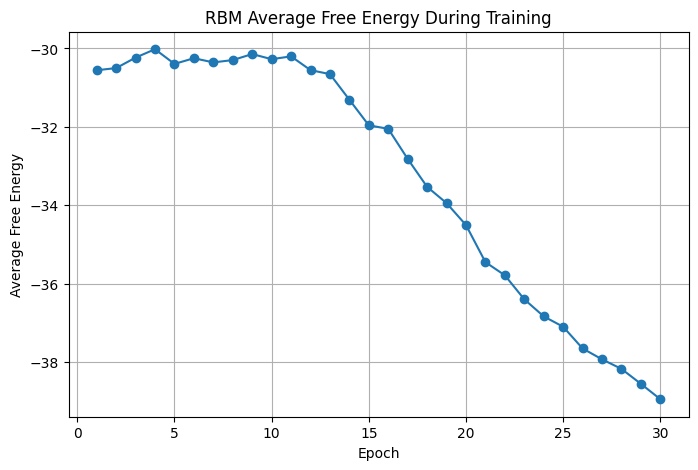


===== RBM ENERGY EXAMPLE =====
Visible vector shape: (64,)
Hidden vector shape: (32,)
Energy E(v,h): -32.3541954571797

===== FINAL PERFORMANCE =====
Final Reconstruction Error: 0.0895

EXPERIMENT 25 COMPLETED SUCCESSFULLY


In [8]:
# EXPERIMENT 25: RESTRICTED BOLTZMANN MACHINE (RBM)
# Energy Function, Contrastive Divergence and Reconstruction

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)

# --------------------------------------------------
# 1. LOAD AND PREPROCESS DIGITS DATASET
# --------------------------------------------------
digits = load_digits()

X = digits.data.astype(np.float32)
images = digits.images

# Normalize pixels to 0–1
X = X / 16.0

# Binarize data
X = (X > 0.5).astype(np.float32)

print("Dataset shape:", X.shape)
print("Visible units:", X.shape[1])

# --------------------------------------------------
# 2. RBM INITIALIZATION
# --------------------------------------------------
n_visible = 64
n_hidden = 32

W = np.random.normal(0, 0.01, (n_visible, n_hidden))
visible_bias = np.zeros(n_visible)
hidden_bias = np.zeros(n_hidden)

learning_rate = 0.05
batch_size = 50
epochs = 30

# --------------------------------------------------
# 3. SIGMOID FUNCTION
# --------------------------------------------------
def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1 / (1 + np.exp(-x))

# --------------------------------------------------
# 4. HIDDEN PROBABILITY P(H|V)
# --------------------------------------------------
def hidden_prob(v):
    return sigmoid(np.dot(v, W) + hidden_bias)

# --------------------------------------------------
# 5. VISIBLE PROBABILITY P(V|H)
# --------------------------------------------------
def visible_prob(h):
    return sigmoid(np.dot(h, W.T) + visible_bias)

# --------------------------------------------------
# 6. ENERGY FUNCTION E(V,H)
# --------------------------------------------------
def energy(v, h):
    return (
        -np.dot(v, visible_bias)
        -np.dot(h, hidden_bias)
        -np.dot(v, np.dot(W, h))
    )

# --------------------------------------------------
# 7. FREE ENERGY FUNCTION
# --------------------------------------------------
def free_energy(v):
    hidden_term = np.logaddexp(
        0, np.dot(v, W) + hidden_bias
    ).sum(axis=1)

    visible_term = np.dot(v, visible_bias)

    return -visible_term - hidden_term

# --------------------------------------------------
# 8. RBM TRAINING USING CD-1
# --------------------------------------------------
reconstruction_errors = []
free_energy_history = []

for epoch in range(epochs):

    np.random.shuffle(X)

    epoch_error = []
    epoch_free_energy = []

    for start in range(0, len(X), batch_size):

        batch = X[start:start + batch_size]

        # Positive phase
        ph0 = hidden_prob(batch)
        h0 = (np.random.rand(*ph0.shape) < ph0).astype(float)

        # Negative phase (one Gibbs step)
        pv1 = visible_prob(h0)
        v1 = (np.random.rand(*pv1.shape) < pv1).astype(float)

        ph1 = hidden_prob(v1)

        # Contrastive Divergence update
        W += learning_rate * (
            np.dot(batch.T, ph0) -
            np.dot(v1.T, ph1)
        ) / len(batch)

        visible_bias += learning_rate * np.mean(
            batch - v1, axis=0
        )

        hidden_bias += learning_rate * np.mean(
            ph0 - ph1, axis=0
        )

        # Reconstruction error
        epoch_error.append(
            np.mean((batch - pv1) ** 2)
        )

        # Free energy
        epoch_free_energy.append(
            np.mean(free_energy(batch))
        )

    reconstruction_errors.append(np.mean(epoch_error))
    free_energy_history.append(np.mean(epoch_free_energy))

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Reconstruction Error: {reconstruction_errors[-1]:.4f} | "
        f"Free Energy: {free_energy_history[-1]:.4f}"
    )

# --------------------------------------------------
# 9. RECONSTRUCTION
# --------------------------------------------------
sample_count = 10
original = X[:sample_count]

hidden = hidden_prob(original)
reconstructed_prob = visible_prob(hidden)

reconstructed_binary = (
    reconstructed_prob > 0.5
).astype(np.float32)

# --------------------------------------------------
# 10. ORIGINAL VS RECONSTRUCTED IMAGES
# --------------------------------------------------
plt.figure(figsize=(14, 4))

for i in range(sample_count):

    # Original image
    plt.subplot(2, sample_count, i+1)
    plt.imshow(original[i].reshape(8, 8), cmap="gray")
    plt.title("Original")
    plt.axis("off")

    # Reconstructed image
    plt.subplot(2, sample_count, sample_count+i+1)
    plt.imshow(
        reconstructed_binary[i].reshape(8, 8),
        cmap="gray"
    )
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("RBM: Original vs Reconstructed Digits")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 11. RECONSTRUCTION ERROR GRAPH
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs+1),
    reconstruction_errors,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error")
plt.title("RBM Reconstruction Error")
plt.grid(True)
plt.show()

# --------------------------------------------------
# 12. FREE ENERGY GRAPH
# --------------------------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs+1),
    free_energy_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Average Free Energy")
plt.title("RBM Average Free Energy During Training")
plt.grid(True)
plt.show()

# --------------------------------------------------
# 13. DISPLAY ENERGY EXAMPLE
# --------------------------------------------------
v_example = original[0]
h_example = hidden_prob(v_example.reshape(1, -1))[0]

h_binary = (
    h_example > 0.5
).astype(float)

print("\n===== RBM ENERGY EXAMPLE =====")
print("Visible vector shape:", v_example.shape)
print("Hidden vector shape:", h_example.shape)
print("Energy E(v,h):", energy(v_example, h_binary))

print("\n===== FINAL PERFORMANCE =====")
print("Final Reconstruction Error:",
      round(reconstruction_errors[-1], 4))

print("\nEXPERIMENT 25 COMPLETED SUCCESSFULLY")